# Đánh giá model CIFAR-10 — Lab 2
Chọn checkpoint ở cell cấu hình, sau đó **Restart Kernel → Run All** với kernel **Python (Lab 2)**. Notebook khôi phục model, suy diễn Test, đối chiếu CSV nếu có, phân tích bốn nhóm dự đoán và Grad-CAM.

Khi chưa có checkpoint, notebook tạo checkpoint ResNet-18 **khởi tạo ngẫu nhiên** và xác minh luồng trên **64 ảnh Test đầu tiên**. Các chỉ số khi đó chỉ kiểm tra kỹ thuật, không thể dùng để kết luận chất lượng model. Checkpoint thực nghiệm sẽ được đánh giá trên đủ 10.000 ảnh Test.

Grad-CAM sử dụng gradient của logit theo lớp để tạo bản đồ kích hoạt thô. [Selvaraju và cộng sự, ICCV 2017](https://openaccess.thecvf.com/content_iccv_2017/html/Selvaraju_Grad-CAM_Visual_Explanations_ICCV_2017_paper.html).

In [1]:
from pathlib import Path
import sys, json, gc
import numpy as np
import pandas as pd
import torch
from torch import nn
from torch.utils.data import DataLoader, Subset
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from IPython.display import display, Markdown

cwd = Path.cwd().resolve()
ROOT = next(p for p in [cwd, *cwd.parents] if (p / "src" / "model_factory.py").exists())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from src.config import CIFAR10_CLASSES, DEFAULT_SEED, DATA_DIR, get_device
from src.dataset import get_cifar10_dataloaders
from src.model_factory import build_model
from src.evaluate import evaluate_test_set
from src.model_analysis import load_analysis_checkpoint, grad_cam, prediction_groups, validate_prediction_csv
from main import set_seed
set_seed(DEFAULT_SEED)
np.random.seed(DEFAULT_SEED)
DEVICE = get_device()
print("Thiết bị", DEVICE, "| PyTorch", torch.__version__)

Thiết bị cuda:0 | PyTorch 2.5.1+cu121


## 1. Chọn checkpoint và cấu hình
`CHECKPOINT_PATH` có thể là đường dẫn tuyệt đối hoặc tương đối với Lab 2. Để trống sẽ chọn checkpoint mới nhất trong `outputs/experiments/`. `CONFIG_OVERRIDE` dành cho checkpoint cũ thiếu metadata, ví dụ `{'model': 'resnet18', 'strategy': 'freeze_all'}`. Strategy không thể suy ra chỉ từ tensor trọng số. Các checkpoint mới có metadata, checkpoint cũ của Lab 2 có thể đọc cấu hình từ tên thực nghiệm.

`PREDICTIONS_CSV` là tùy chọn. Notebook vẫn suy diễn mới để tính loss và kiểm tra CSV có khớp checkpoint, ID ảnh và xác suất hay không. Các ngưỡng confidence cố định được in ở dưới, nhóm rỗng được ghi rõ.

In [2]:
# Nghiệm thu EXP_02, chọn theo Validation Accuracy 94,35% (epoch 13).
CHECKPOINT_PATH = "outputs/experiments/resnet18_unfreeze_last_block_20261121_115234_018455_f40df826/checkpoints/best_resnet18_unfreeze_last_block_20261121_115234_018455_f40df826.pth"
CONFIG_OVERRIDE = None
PREDICTIONS_CSV = "outputs/experiments/resnet18_unfreeze_last_block_20261121_115234_018455_f40df826/predictions.csv"  # Đổi cùng checkpoint hoặc để trống
HIGH_CONFIDENCE = 0.80
LOW_CONFIDENCE = 0.50
EXAMPLES_PER_GROUP = 4

def resolve_project_path(value):
    path = Path(value).expanduser()
    return path if path.is_absolute() else ROOT / path

if CHECKPOINT_PATH:
    checkpoint_path = resolve_project_path(CHECKPOINT_PATH)
else:
    candidates = sorted((ROOT / "outputs" / "experiments").glob("*/checkpoints/*.pth"), key=lambda p: p.stat().st_mtime)
    checkpoint_path = candidates[-1] if candidates else None
if checkpoint_path is None:
    fixture_dir = ROOT / "outputs" / "verification" / "verification_random_resnet18"
    fixture_dir.mkdir(parents=True, exist_ok=True)
    fixture = build_model("resnet18", "freeze_all", pretrained=False)
    checkpoint_path = fixture_dir / "verification_random_resnet18.pth"
    torch.save({"model_state_dict": fixture.state_dict(),
                "config": {**fixture.lab2_config, "verification_only": True}}, checkpoint_path)
    del fixture
    gc.collect()

model, config = load_analysis_checkpoint(checkpoint_path, DEVICE, CONFIG_OVERRIDE)
VERIFICATION_ONLY = bool(config.get("verification_only", False))
ANALYSIS_DIR = ROOT / "outputs" / "model_analysis" / checkpoint_path.stem
ANALYSIS_DIR.mkdir(parents=True, exist_ok=True)
print("Checkpoint:", checkpoint_path)
print("Cấu hình:", config)
print("Ngưỡng cao >=", HIGH_CONFIDENCE, "| Ngưỡng thấp <=", LOW_CONFIDENCE)
if VERIFICATION_ONLY:
    display(Markdown("**XÁC MINH KỸ THUẬT — trọng số ngẫu nhiên, 64 ảnh Test. Chưa có kết quả thực nghiệm.**"))
else:
    display(Markdown("**Đánh giá checkpoint đã chọn trên 10.000 ảnh Test.**"))
saved_figures = []

def save_show(fig, filename):
    path = ANALYSIS_DIR / filename
    fig.savefig(path, dpi=180, bbox_inches="tight")
    saved_figures.append(path)
    plt.show()
    plt.close(fig)

Checkpoint: D:\CODE\HKND\CODE\reference_project\lab2\checkpoints\best_resnet18_unfreeze_last_block_20261121_115234_018455_f40df826.pth
Cấu hình: {'model': 'resnet18', 'strategy': 'unfreeze_last_block', 'num_classes': 10}
Ngưỡng cao >= 0.8 | Ngưỡng thấp <= 0.5


**Đánh giá checkpoint đã chọn trên 10.000 ảnh Test.**

## 2. Test và chỉ số đánh giá
Dùng loader từ `src/dataset.py` với seed cấu hình và transform Eval của pipeline. Checkpoint được nạp với kiểm tra shape nghiêm ngặt. Chọn checkpoint tốt nhất bằng Validation Accuracy trước khi xem kết quả Test.

In [3]:
tr, va, te = get_cifar10_dataloaders(
    data_dir=str(DATA_DIR), batch_size=32, num_workers=0,
    pin_memory=DEVICE.type == "cuda", subset_ratio=1.0, dry_run=False, seed=DEFAULT_SEED)
test_subset = te.dataset
del tr, va
gc.collect()
if VERIFICATION_ONLY:
    test_subset = Subset(test_subset, list(range(64)))
test_loader = DataLoader(test_subset, batch_size=64, shuffle=False, num_workers=0)
results = evaluate_test_set(model, test_loader, nn.CrossEntropyLoss(), DEVICE, CIFAR10_CLASSES)
frame = pd.DataFrame(results["predictions"])
assert len(frame) == (64 if VERIFICATION_ONLY else 10000)
assert frame.sample_index.is_unique
if PREDICTIONS_CSV:
    cached = validate_prediction_csv(resolve_project_path(PREDICTIONS_CSV), frame)
    print("CSV khớp suy diễn mới:", len(cached), "ảnh.")
report = results["classification_report_dict"]
display(pd.DataFrame([{
    "samples": len(frame), "loss": results["test_loss"], "accuracy_pct": results["overall_acc"],
    "macro_precision": report["macro avg"]["precision"], "macro_recall": report["macro avg"]["recall"],
    "macro_f1": report["macro avg"]["f1-score"], "weighted_f1": report["weighted avg"]["f1-score"],
    "verification_only": VERIFICATION_ONLY,
}]))
display(pd.DataFrame(report).T.round(4))
frame.to_csv(ANALYSIS_DIR / "predictions.csv", index=False)
with (ANALYSIS_DIR / "analysis_metrics.json").open("w", encoding="utf-8") as stream:
    json.dump({"checkpoint": str(checkpoint_path), "config": config, "samples": len(frame),
               "verification_only": VERIFICATION_ONLY, "loss": results["test_loss"],
               "accuracy_pct": results["overall_acc"], "classification_report": report},
              stream, ensure_ascii=False, indent=2)

Files already downloaded and verified
Files already downloaded and verified
KET QUA DANH GIA TREN TAP TEST DOC LAP (10000 ANH)
  Test Loss            : 0.2304
  Top-1 Overall Accuracy: 93.63%

Per-Class Accuracy Breakdown:
----------------------------------------------------------------------
  Class airplane    :  97.60%
  Class automobile  :  96.40%
  Class bird        :  90.80%
  Class cat         :  82.50%
  Class deer        :  95.60%
  Class dog         :  90.10%
  Class frog        :  96.80%
  Class horse       :  95.40%
  Class ship        :  96.10%
  Class truck       :  95.00%
----------------------------------------------------------------------

Detailed Classification Report:
              precision    recall  f1-score   support

    airplane     0.9208    0.9760    0.9476      1000
  automobile     0.9621    0.9640    0.9630      1000
        bird     0.9409    0.9080    0.9242      1000
         cat     0.9106    0.8250    0.8657      1000
        deer     0.9140    0.95

,samples,loss,accuracy_pct,macro_precision,macro_recall,macro_f1,weighted_f1,verification_only
0,10000,0.230386,93.63,0.936486,0.9363,0.935978,0.935978,False


,precision,recall,f1-score,support
airplane,0.9208,0.9760,0.9476,1000.0000
automobile,0.9621,0.9640,0.9630,1000.0000
bird,0.9409,0.9080,0.9242,1000.0000
cat,0.9106,0.8250,0.8657,1000.0000
deer,0.9140,0.9560,0.9345,1000.0000
dog,0.8816,0.9010,0.8912,1000.0000
frog,0.9371,0.9680,0.9523,1000.0000
horse,0.9617,0.9540,0.9578,1000.0000
ship,0.9688,0.9610,0.9649,1000.0000
truck,0.9674,0.9500,0.9586,1000.0000


**Nhận xét.** Accuracy đo tỷ lệ dự đoán trùng nhãn chuẩn. Macro Precision/Recall/F1 coi trọng mỗi lớp như nhau, weighted F1 tính theo số mẫu từng lớp. Confidence là xác suất softmax, chưa qua kiểm tra calibration. Trong chế độ xác minh, mọi con số thuộc model ngẫu nhiên và mẫu nhỏ.

## 3. Confusion matrix và các cặp nhầm lớp

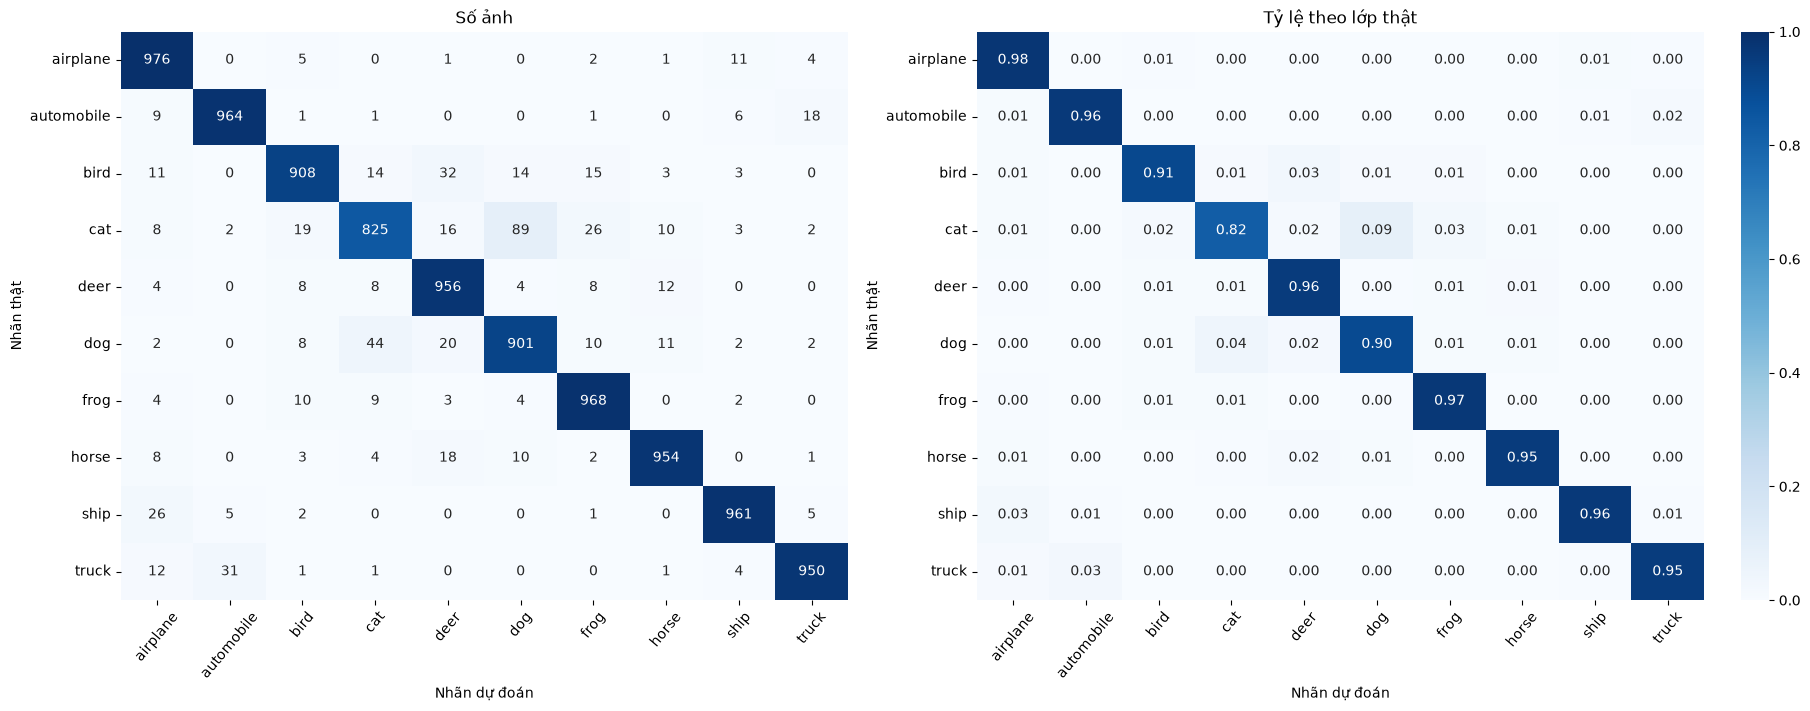

,true_label,predicted_label,errors,fraction_of_true_class
23,cat,dog,89,0.089
36,dog,cat,44,0.044
14,bird,deer,32,0.032
61,truck,automobile,31,0.031
24,cat,frog,26,0.026
55,ship,airplane,26,0.026
37,dog,deer,20,0.020
21,cat,bird,19,0.019
11,automobile,truck,18,0.018
51,horse,deer,18,0.018


,predicted_samples
predicted_label,
airplane,1060
deer,1046
frog,1033
dog,1022
automobile,1002
ship,992
horse,992
truck,982
bird,965


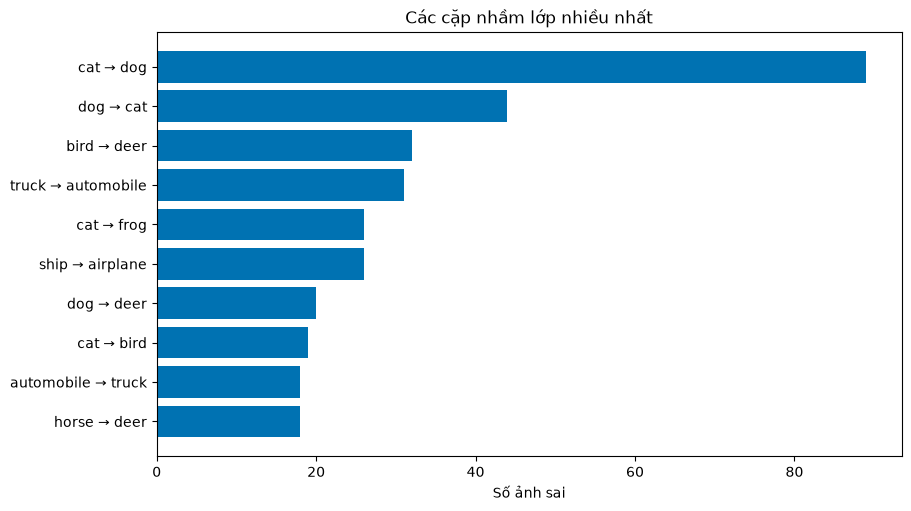

In [4]:
cm = results["confusion_matrix"]
normalized_cm = np.divide(cm, cm.sum(axis=1, keepdims=True),
                          out=np.zeros_like(cm, dtype=float), where=cm.sum(axis=1, keepdims=True) != 0)
fig, axes = plt.subplots(1, 2, figsize=(18, 7), layout="constrained")
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=CIFAR10_CLASSES,
            yticklabels=CIFAR10_CLASSES, ax=axes[0], cbar=False)
sns.heatmap(normalized_cm, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1,
            xticklabels=CIFAR10_CLASSES, yticklabels=CIFAR10_CLASSES, ax=axes[1])
for ax, title in zip(axes, ["Số ảnh", "Tỷ lệ theo lớp thật"]):
    ax.set(title=title, xlabel="Nhãn dự đoán", ylabel="Nhãn thật")
    ax.tick_params(axis="x", rotation=50)
    ax.tick_params(axis="y", rotation=0)
save_show(fig, "confusion_matrices.png")
pairs = pd.DataFrame([
    {"true_label": CIFAR10_CLASSES[i], "predicted_label": CIFAR10_CLASSES[j],
     "errors": int(cm[i, j]), "fraction_of_true_class": float(normalized_cm[i, j])}
    for i in range(10) for j in range(10) if i != j and cm[i, j] > 0
]).sort_values("errors", ascending=False) if (cm.sum() - cm.trace()) else pd.DataFrame()
display(pairs.head(10))
predicted_counts = frame.predicted_label.value_counts()
display(predicted_counts.rename('predicted_samples').to_frame())
if len(predicted_counts) == 1:
    only_class = predicted_counts.index[0]
    matches = int((frame.true_label == only_class).sum())
    display(Markdown(f'Model dự đoán **{only_class} cho cả {len(frame)} ảnh**. Có {matches} ảnh thật thuộc lớp đó nên được tính đúng, còn {len(frame) - matches} ảnh thuộc lớp khác bị tính sai. Đây là bằng chứng trực tiếp về xu hướng dồn dự đoán vào một lớp trong lần chạy này.'))
if len(pairs):
    fig, ax = plt.subplots(figsize=(9, 5), layout="constrained")
    top = pairs.head(10).iloc[::-1]
    ax.barh(top.true_label + " → " + top.predicted_label, top.errors, color="#0072B2")
    ax.set(xlabel="Số ảnh sai", title="Các cặp nhầm lớp nhiều nhất")
    save_show(fig, "top_confusions.png")

**Nhận xét.** Mỗi ô dùng hướng nhãn thật → nhãn dự đoán. So sánh cả số ảnh sai và tỷ lệ theo lớp thật khi số mẫu khác nhau. Một cặp nhầm nhiều cần xem ảnh cụ thể để phân biệt ảnh mờ, đối tượng nhỏ, nền gây nhiễu hoặc model chưa học đủ. Ma trận riêng lẻ chưa xác định được nguyên nhân.

## 4. Bốn nhóm dự đoán và Top-3
Chỉ lấy ảnh thật thuộc nhóm thỏa ngưỡng. Trường hợp không có ảnh trong nhóm được hiển thị rõ.

### Đúng — confidence cao

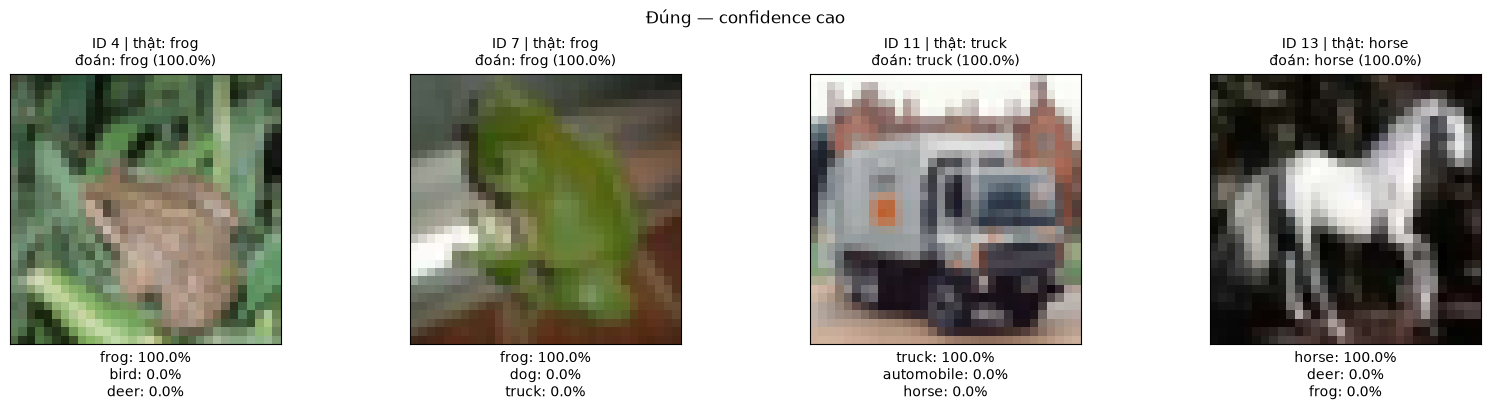

### Đúng — confidence thấp

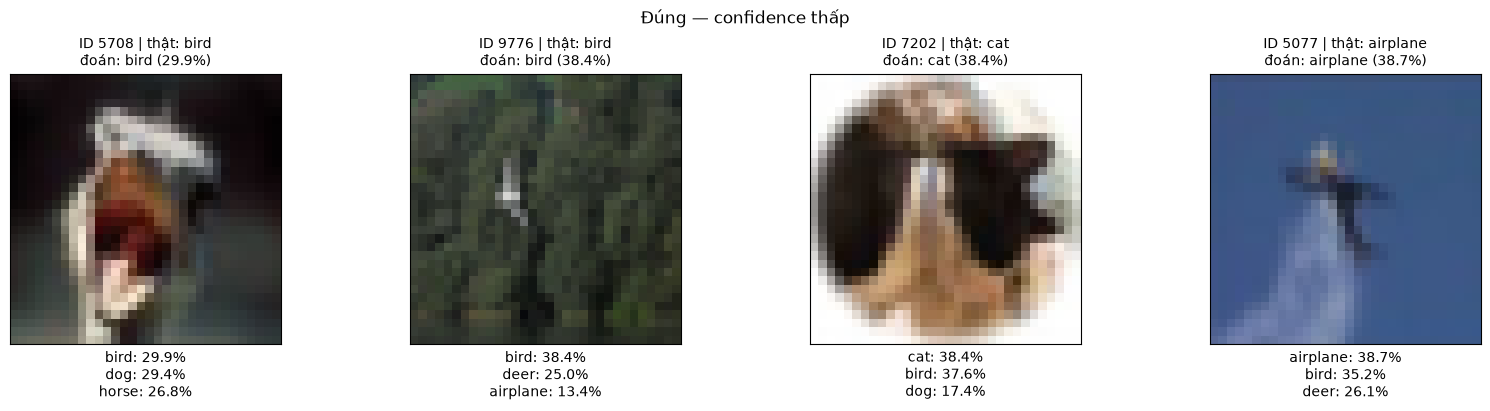

### Sai — confidence cao

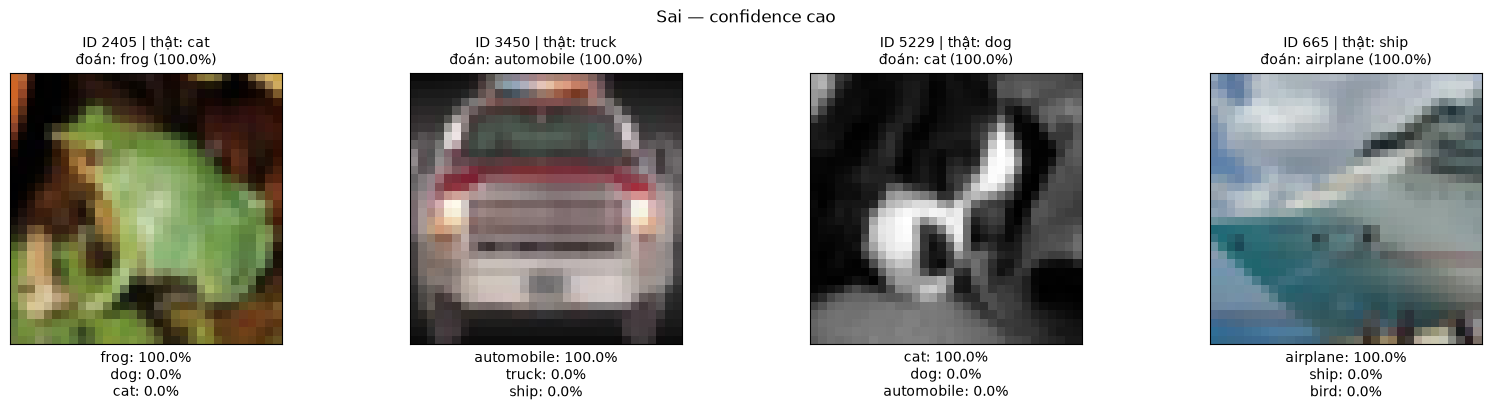

### Sai — confidence thấp

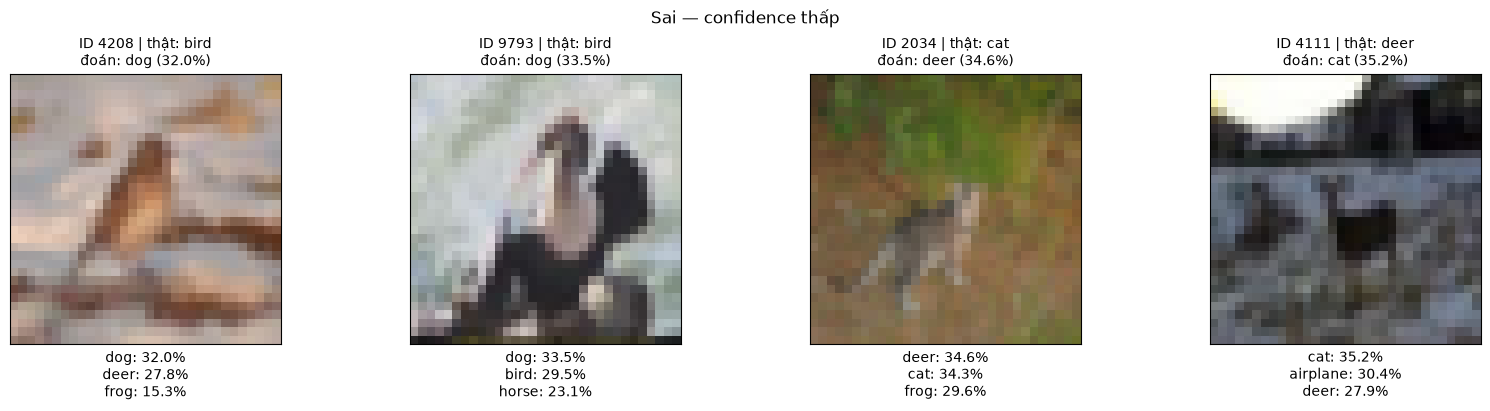

In [5]:
raw_test = te.dataset.dataset
def raw_image(sample_index):
    return raw_test.data[int(sample_index)]

groups = prediction_groups(frame, HIGH_CONFIDENCE, LOW_CONFIDENCE, EXAMPLES_PER_GROUP)
for number, (title, group) in enumerate(groups.items(), 1):
    display(Markdown("### " + title))
    if group.empty:
        display(Markdown("Không có ảnh thỏa ngưỡng trong lần đánh giá này."))
        continue
    fig, axes = plt.subplots(1, len(group), figsize=(4 * len(group), 4), squeeze=False, layout="constrained")
    for ax, (_, row) in zip(axes[0], group.iterrows()):
        ax.imshow(raw_image(row.sample_index), interpolation="nearest")
        top3 = "\n".join(f"{row[f'top{k}_label']}: {row[f'top{k}_probability']:.1%}" for k in range(1, 4))
        ax.set_title(f"ID {int(row.sample_index)} | thật: {row.true_label}\n"
                     f"đoán: {row.predicted_label} ({row.confidence:.1%})", fontsize=10)
        ax.set_xlabel(top3, fontsize=10)
        ax.set_xticks([]); ax.set_yticks([])
    fig.suptitle(title + (" — model ngẫu nhiên" if VERIFICATION_ONLY else ""))
    save_show(fig, f"group_{number}.png")

**Nhận xét.** Dự đoán đúng thiếu tự tin và dự đoán sai tự tin cao là hai loại cần xem kỹ khi sử dụng model. Nhãn đúng/sai được tính bằng so sánh với ground truth của CIFAR-10. Những ảnh có confidence nằm giữa hai ngưỡng không thuộc bốn nhóm trên. Không dùng nhóm ít mẫu để suy ra chất lượng toàn bộ model.

## 5. Grad-CAM và phân tích từng trường hợp
Mỗi ví dụ hiển thị ảnh gốc, heatmap lớp dự đoán và heatmap lớp thật. Màu nóng biểu thị mức kích hoạt tương đối cao sau chuẩn hóa riêng từng heatmap. Hai bản đồ không cùng thang cường độ tuyệt đối. Bản đồ toàn 0 được ghi rõ.

Phần che vùng ảnh thay phần 20% pixel có CAM cao nhất bằng giá trị trung bình ImageNet (0 trong tensor đã chuẩn hóa), rồi đo thay đổi xác suất của lớp dự đoán. Đây là thử độ nhạy, có thể tạo ảnh ngoài phân phối.

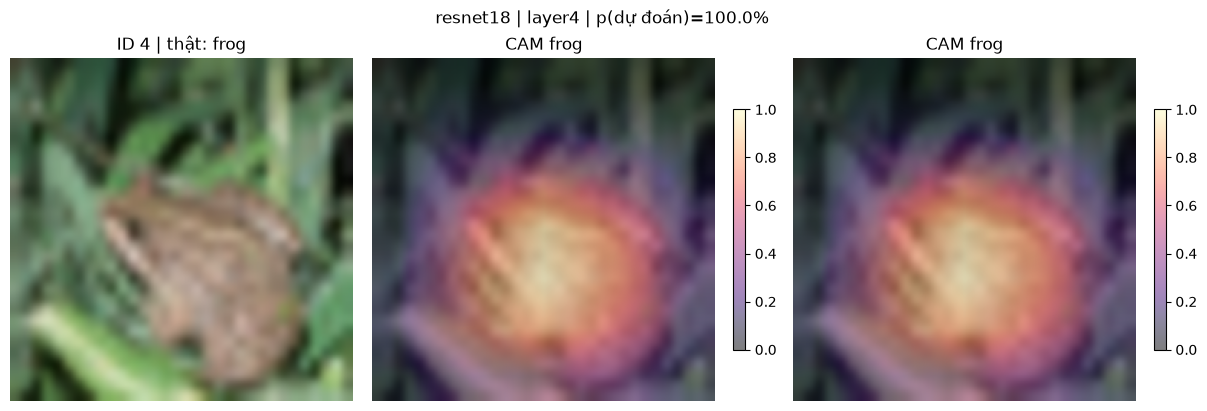

**Ảnh 4 — đúng.** Ground truth là **frog**, model chọn **frog**. Top-3 gồm frog (100.0%), bird (0.0%), deer (0.0%). Chênh Top-1 và Top-2 là 100.0%. Sau khi che vùng CAM cao, xác suất lớp dự đoán là 0.2%, chênh lệch so với ban đầu -99.8%.

Đối chiếu ảnh gốc và hai heatmap để quan sát vùng vật thể, đường nét, màu và nền. Nếu vùng nóng phủ nền hoặc một phần rất nhỏ của vật thể, đó là gợi ý cần kiểm tra thêm. Bằng chứng hiện tại chưa đủ khẳng định đặc điểm nào gây ra quyết định. Ghi nhận hình dạng, độ rõ và vùng nóng quan sát được trước khi kết luận nguyên nhân.

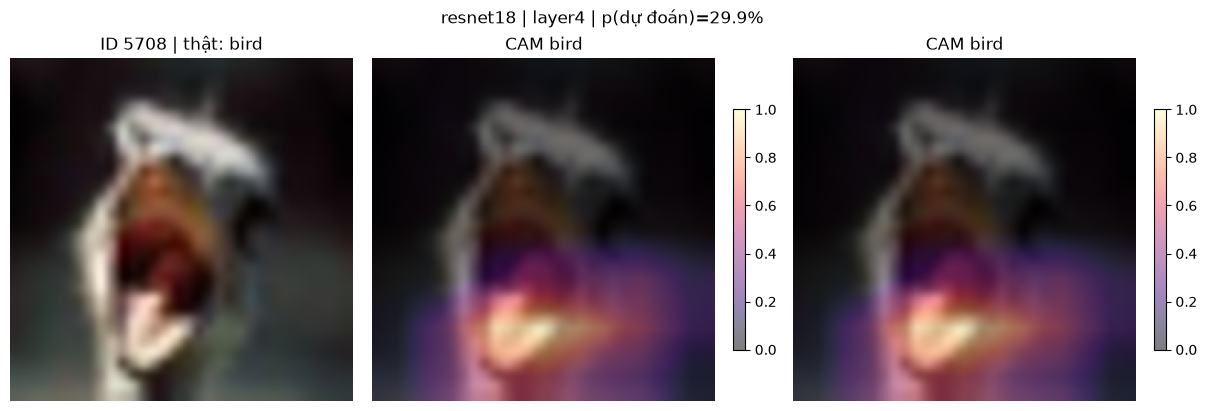

**Ảnh 5708 — đúng.** Ground truth là **bird**, model chọn **bird**. Top-3 gồm bird (29.9%), dog (29.4%), horse (26.8%). Chênh Top-1 và Top-2 là 0.5%. Sau khi che vùng CAM cao, xác suất lớp dự đoán là 55.3%, chênh lệch so với ban đầu +25.4%.

Đối chiếu ảnh gốc và hai heatmap để quan sát vùng vật thể, đường nét, màu và nền. Nếu vùng nóng phủ nền hoặc một phần rất nhỏ của vật thể, đó là gợi ý cần kiểm tra thêm. Bằng chứng hiện tại chưa đủ khẳng định đặc điểm nào gây ra quyết định. Ghi nhận hình dạng, độ rõ và vùng nóng quan sát được trước khi kết luận nguyên nhân.

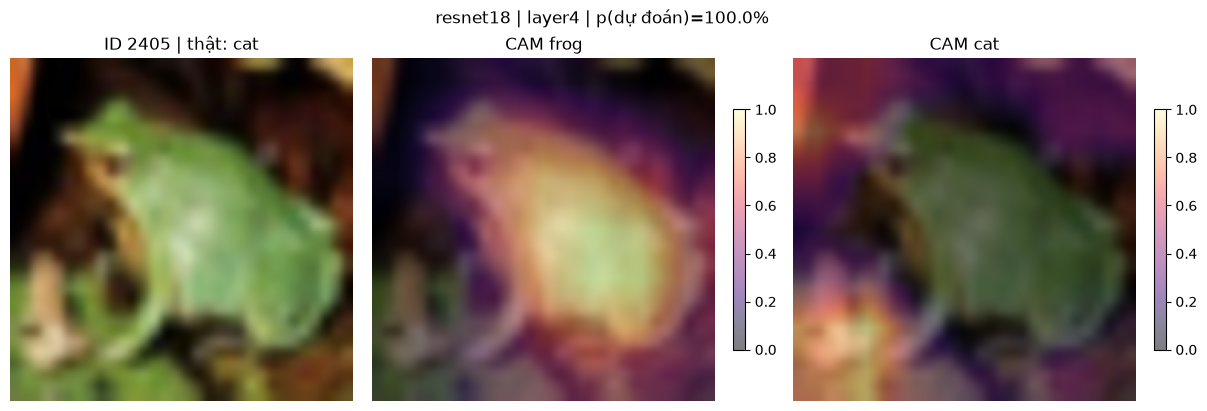

**Ảnh 2405 — sai.** Ground truth là **cat**, model chọn **frog**. Top-3 gồm frog (100.0%), dog (0.0%), cat (0.0%). Chênh Top-1 và Top-2 là 100.0%. Sau khi che vùng CAM cao, xác suất lớp dự đoán là 0.1%, chênh lệch so với ban đầu -99.9%.

Đối chiếu ảnh gốc và hai heatmap để quan sát vùng vật thể, đường nét, màu và nền. Nếu vùng nóng phủ nền hoặc một phần rất nhỏ của vật thể, đó là gợi ý cần kiểm tra thêm. Bằng chứng hiện tại chưa đủ khẳng định đặc điểm nào gây ra quyết định. Ghi nhận hình dạng, độ rõ và vùng nóng quan sát được trước khi kết luận nguyên nhân.

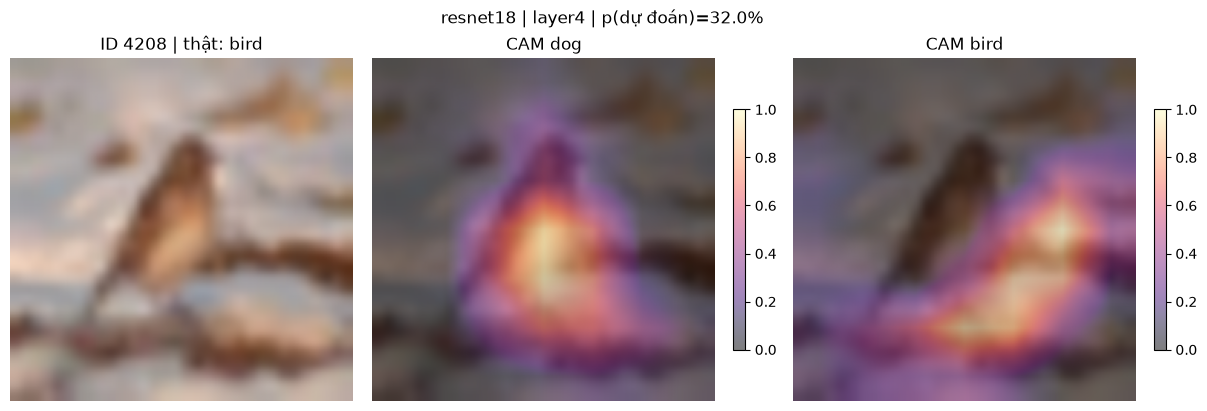

**Ảnh 4208 — sai.** Ground truth là **bird**, model chọn **dog**. Top-3 gồm dog (32.0%), deer (27.8%), frog (15.3%). Chênh Top-1 và Top-2 là 4.2%. Sau khi che vùng CAM cao, xác suất lớp dự đoán là 0.0%, chênh lệch so với ban đầu -32.0%.

Đối chiếu ảnh gốc và hai heatmap để quan sát vùng vật thể, đường nét, màu và nền. Nếu vùng nóng phủ nền hoặc một phần rất nhỏ của vật thể, đó là gợi ý cần kiểm tra thêm. Bằng chứng hiện tại chưa đủ khẳng định đặc điểm nào gây ra quyết định. Ghi nhận hình dạng, độ rõ và vùng nóng quan sát được trước khi kết luận nguyên nhân.

In [6]:
candidate_rows = []
for correct in [True, False]:
    subset = frame[(frame.true_label == frame.predicted_label) == correct]
    if len(subset):
        candidate_rows.extend([subset.nlargest(1, "confidence").iloc[0],
                               subset.nsmallest(1, "confidence").iloc[0]])
cases = pd.DataFrame(candidate_rows).drop_duplicates("sample_index") if candidate_rows else pd.DataFrame()
for _, row in cases.iterrows():
    sample_id = int(row.sample_index)
    image = Image.fromarray(raw_image(sample_id))
    tensor = raw_test.transform(image).unsqueeze(0).to(DEVICE)
    predicted_id = CIFAR10_CLASSES.index(row.predicted_label)
    true_id = CIFAR10_CLASSES.index(row.true_label)
    cam, layer = grad_cam(model, tensor, predicted_id)
    true_cam, _ = grad_cam(model, tensor, true_id)
    display_image = np.asarray(image.resize((224, 224))) / 255.0
    fig, axes = plt.subplots(1, 3, figsize=(12, 4), layout="constrained")
    axes[0].imshow(display_image)
    axes[0].set_title(f"ID {sample_id} | thật: {row.true_label}")
    for ax, heatmap, label in [(axes[1], cam, row.predicted_label), (axes[2], true_cam, row.true_label)]:
        ax.imshow(display_image)
        if heatmap.max() > 0:
            overlay = ax.imshow(heatmap, cmap="magma", alpha=.5, vmin=0, vmax=1)
            fig.colorbar(overlay, ax=ax, shrink=.7)
        ax.set_title(f"CAM {label}" + (" | toàn 0" if heatmap.max() == 0 else ""))
    for ax in axes:
        ax.axis("off")
    fig.suptitle(f"{config['model']} | {layer} | p(dự đoán)={row.confidence:.1%}")
    save_show(fig, f"gradcam_{sample_id}.png")
    if cam.max() > 0:
        pixel_ids = np.argsort(cam.ravel(), kind="stable")[-max(1, cam.size // 5):]
        mask = np.zeros(cam.size, dtype=bool)
        mask[pixel_ids] = True
        mask = torch.tensor(mask.reshape(cam.shape), device=DEVICE)
        masked = tensor.clone()
        masked[:, :, mask] = 0
        with torch.no_grad():
            masked_probability = model(masked).softmax(1)[0, predicted_id].item()
        sensitivity = f"Sau khi che vùng CAM cao, xác suất lớp dự đoán là {masked_probability:.1%}, chênh lệch so với ban đầu {masked_probability - row.confidence:+.1%}."
    else:
        sensitivity = "CAM toàn 0, chưa có vùng kích hoạt dương để kiểm tra che vùng."
    top3 = ", ".join(f"{row[f'top{k}_label']} ({row[f'top{k}_probability']:.1%})" for k in range(1, 4))
    is_correct = row.true_label == row.predicted_label
    display(Markdown(
        f"**Ảnh {sample_id} — {'đúng' if is_correct else 'sai'}.** Ground truth là **{row.true_label}**, "
        f"model chọn **{row.predicted_label}**. Top-3 gồm {top3}. "
        f"Chênh Top-1 và Top-2 là {row.margin_top1_top2:.1%}. {sensitivity}\n\n"
        "Đối chiếu ảnh gốc và hai heatmap để quan sát vùng vật thể, đường nét, màu và nền. "
        "Nếu vùng nóng phủ nền hoặc một phần rất nhỏ của vật thể, đó là gợi ý cần kiểm tra thêm. "
        "Bằng chứng hiện tại chưa đủ khẳng định đặc điểm nào gây ra quyết định. "
        + ("Model này khởi tạo ngẫu nhiên nên không diễn giải CAM thành đặc trưng đã học." if VERIFICATION_ONLY else
           "Ghi nhận hình dạng, độ rõ và vùng nóng quan sát được trước khi kết luận nguyên nhân.")
    ))

**Giới hạn diễn giải.** Grad-CAM cho biết vùng liên quan đến gradient của một lớp tại ảnh đã chọn. Bản đồ thô và phép che vùng không chứng minh quan hệ nhân quả. Notebook không có bounding box hay nhãn segmentation để định lượng vùng vật thể, vì vậy nhận xét vị trí vật thể cần kiểm tra trực quan. Khi có checkpoint thật, bổ sung nhận xét theo từng trường hợp sau khi xem hình và đối chiếu lớp cạnh tranh.

In [7]:
for path in saved_figures:
    assert path.is_file() and path.stat().st_size > 0
if VERIFICATION_ONLY and set(cases.sample_index.astype(int)) == {13, 48, 21, 32}:
    display(Markdown('### Quan sát trực quan của lần xác minh đã lưu'))
    display(pd.DataFrame([
        {'ID': 13, 'quan_sat': 'Ngựa trắng trên nền tối; CAM horse phủ cả vùng thân và chân. Hai CAM giống nhau vì lớp thật và lớp dự đoán đều là horse.'},
        {'ID': 48, 'quan_sat': 'Ngựa nâu trên nền xanh; vùng CAM trải rộng qua đầu, thân và một phần nền. Khoảng cách Top-1/Top-2 nhỏ, chưa thể kết luận model nhận diện hình dạng ngựa.'},
        {'ID': 21, 'quan_sat': 'Máy bay có hình tối trên nền sáng; CAM horse lan qua cả nền và vật thể, CAM airplane có vùng sáng trên nền phía trên. Dự đoán sai dù hình dáng máy bay rõ với người xem.'},
        {'ID': 32, 'quan_sat': 'Hươu nhỏ trong ảnh nhiều nền; CAM horse lan qua vùng giữa ảnh, CAM deer tập trung gần biên phải. Cần phân biệt vật thể và nền bằng bằng chứng bổ sung.'},
    ]))
    display(Markdown('Các quan sát trên được kiểm tra bằng hình của checkpoint ngẫu nhiên trong lần xác minh này. Model chưa được huấn luyện và dồn mọi dự đoán vào horse, nên các ảnh ngựa đúng chưa chứng minh khả năng phân biệt lớp.'))
for path in saved_figures:
    assert path.is_file() and path.stat().st_size > 0
assert np.isclose((frame.true_label == frame.predicted_label).mean() * 100, results["overall_acc"])
print("Đã kiểm tra", len(frame), "dự đoán và", len(saved_figures), "hình.")
print("Đầu ra:", ANALYSIS_DIR)
print("Verification only:", VERIFICATION_ONLY)

Đã kiểm tra 10000 dự đoán và 10 hình.
Đầu ra: D:\CODE\HKND\CODE\reference_project\lab2\outputs\model_analysis\best_resnet18_unfreeze_last_block_20261121_115234_018455_f40df826
Verification only: False
